In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import ttest_ind
from sklearn.linear_model import LinearRegression

from problems import ICS26_DIR

/home/prajwal/github-repos/knnsur/src/__init__.py:17: UserWarning: CuPy not available; GPU acceleration will be disabled.
  warnings.warn(msg)


In [ ]:
subdirs = [d.name for d in ICS26_DIR.iterdir() if d.is_dir()]
print(subdirs)

['adaptive_clustering_global_vs_local', 'adaptive_clustering_global_vs_n_init_clusters', 'adaptive_clustering_global_local_vs_min_pts_per_cluster', 'mahalanobis_knn_containment', 'rosenbrock_convergence']


# Adaptive Clustering: Global vs Local Error Type

In [ ]:
adaptive_clustering_dir = ICS26_DIR / "adaptive_clustering_global_vs_local"
csv_path = adaptive_clustering_dir / "summary.csv"

df_ac_gl = pd.read_csv(csv_path)

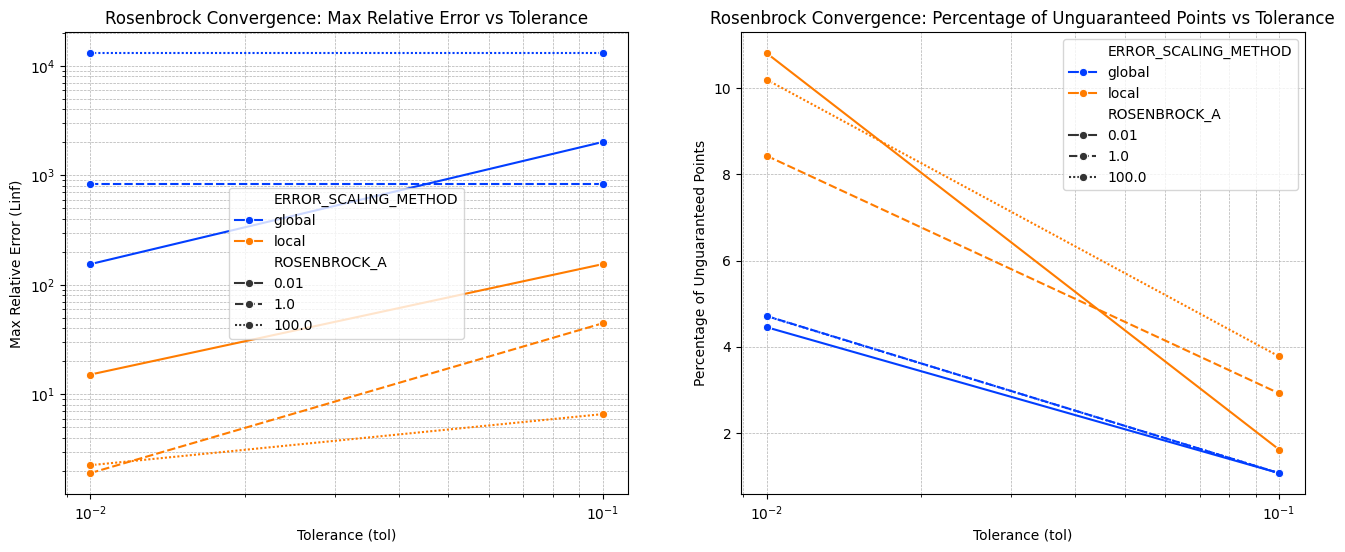

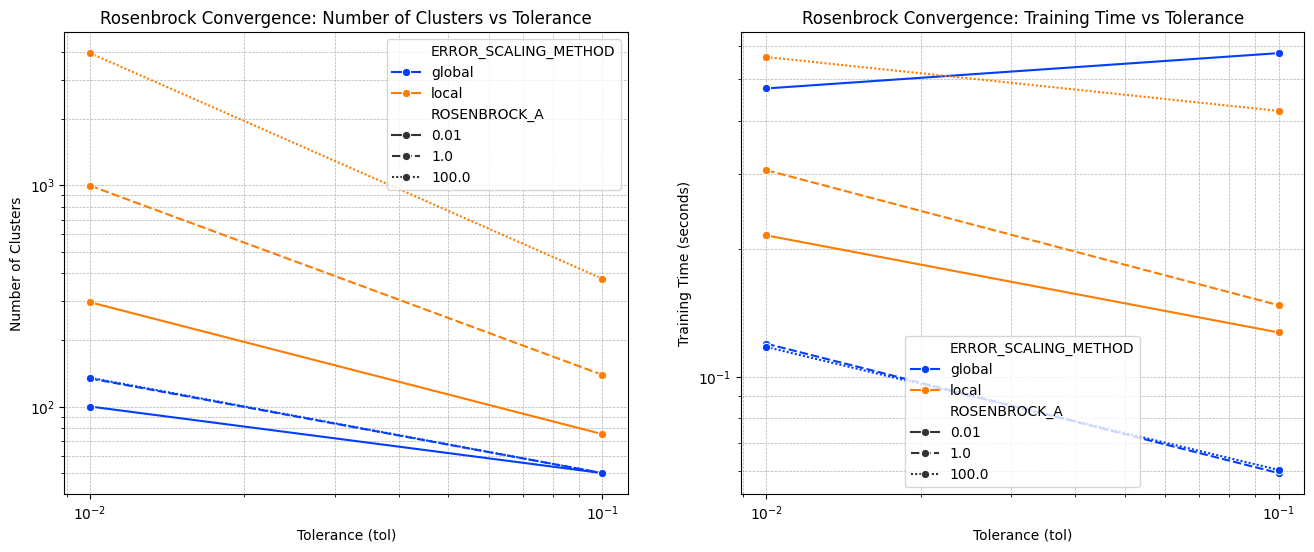

In [ ]:
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_ac_gl,
    x="tol",
    y="max_rel_error_linf",
    hue="ERROR_SCALING_METHOD",
    style="ROSENBROCK_A",
    marker="o",
    palette="bright",
)

plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Max Relative Error (Linf)")
plt.title("Rosenbrock Convergence: Max Relative Error vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_ac_gl,
    x="tol",
    y="perct_ungauranteed",
    hue="ERROR_SCALING_METHOD",
    style="ROSENBROCK_A",
    marker="o",
    palette="bright",
)
plt.xscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Percentage of Unguaranteed Points")
plt.title("Rosenbrock Convergence: Percentage of Unguaranteed Points vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_ac_gl,
    x="tol",
    y="n_clusters",
    hue="ERROR_SCALING_METHOD",
    style="ROSENBROCK_A",
    marker="o",
    palette="bright",
)

plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Number of Clusters")
plt.title("Rosenbrock Convergence: Number of Clusters vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_ac_gl,
    x="tol",
    y="train_time_sec",
    hue="ERROR_SCALING_METHOD",
    style="ROSENBROCK_A",
    marker="o",
    palette="bright",
)
plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Training Time (seconds)")
plt.title("Rosenbrock Convergence: Training Time vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

### Comparing Means of max_rel_error_linf for global vs local (varying Rosenbrock A)

In [ ]:
err_col = "max_rel_error_linf"
global_array = df_ac_gl[df_ac_gl["ERROR_SCALING_METHOD"] == "global"][err_col]
local_array = df_ac_gl[df_ac_gl["ERROR_SCALING_METHOD"] == "local"][err_col]

t_stat, p_val = ttest_ind(global_array, local_array)
print(f"T-stat: {t_stat:.1e}, p-val: {p_val*100:.1f}%")

T-stat: 1.9e+00, p-val: 8.2%


### Comparing Means of n_clusters for global vs local (varying Rosenbrock A)

In [ ]:
cluster_col = "n_clusters"
global_array = df_ac_gl[df_ac_gl["ERROR_SCALING_METHOD"] == "global"][cluster_col]
local_array = df_ac_gl[df_ac_gl["ERROR_SCALING_METHOD"] == "local"][cluster_col]

t_stat, p_val = ttest_ind(global_array, local_array)
print(f"T-stat: {t_stat:.1e}, p-val: {p_val*100:.1f}%")

T-stat: -1.5e+00, p-val: 17.8%


# Adaptive Clustering: Variation of Num of Initial CLusters

In [ ]:
ac_n_init_dir = ICS26_DIR / "adaptive_clustering_global_vs_n_init_clusters"
csv_path = ac_n_init_dir / "summary.csv"

df_ac_ninit = pd.read_csv(csv_path)

Text(0.5, 1.0, 'Correlation Heatmap: Varying N_INIT_CLUSTERS')

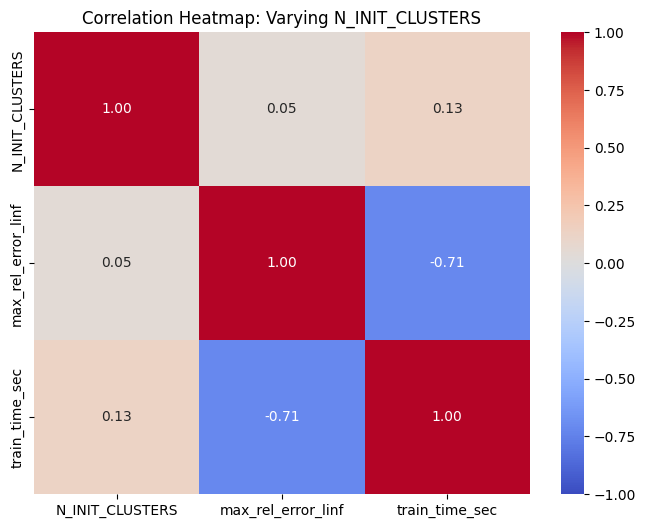

In [ ]:
cols = ["N_INIT_CLUSTERS", "max_rel_error_linf", "train_time_sec"]
corr_df = df_ac_ninit[cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr_df, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap: Varying N_INIT_CLUSTERS")

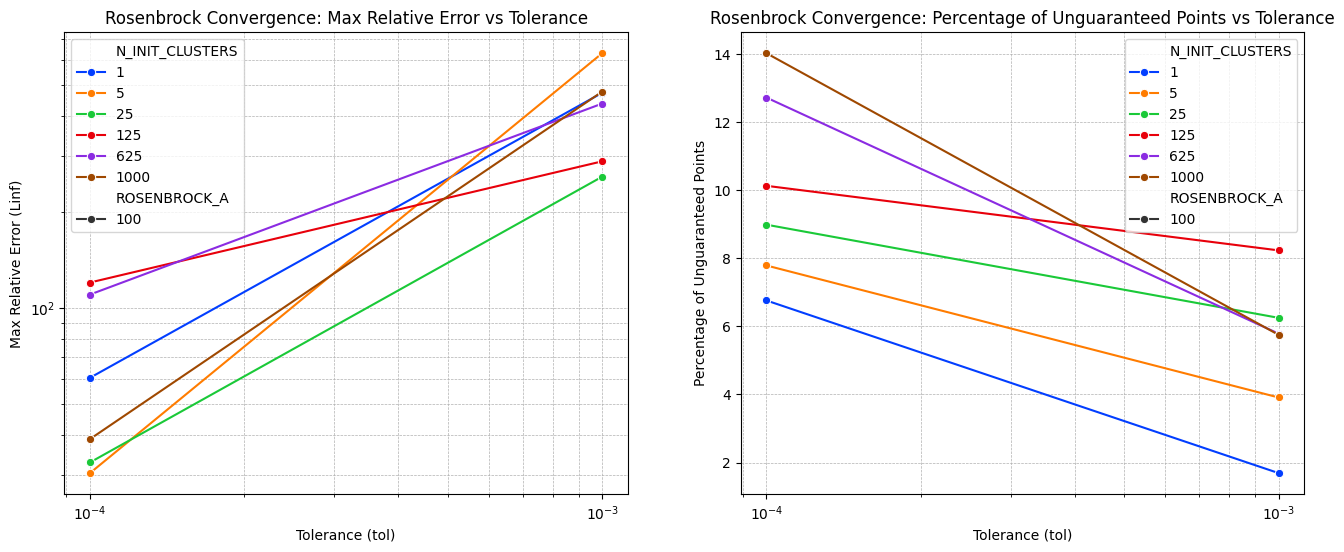

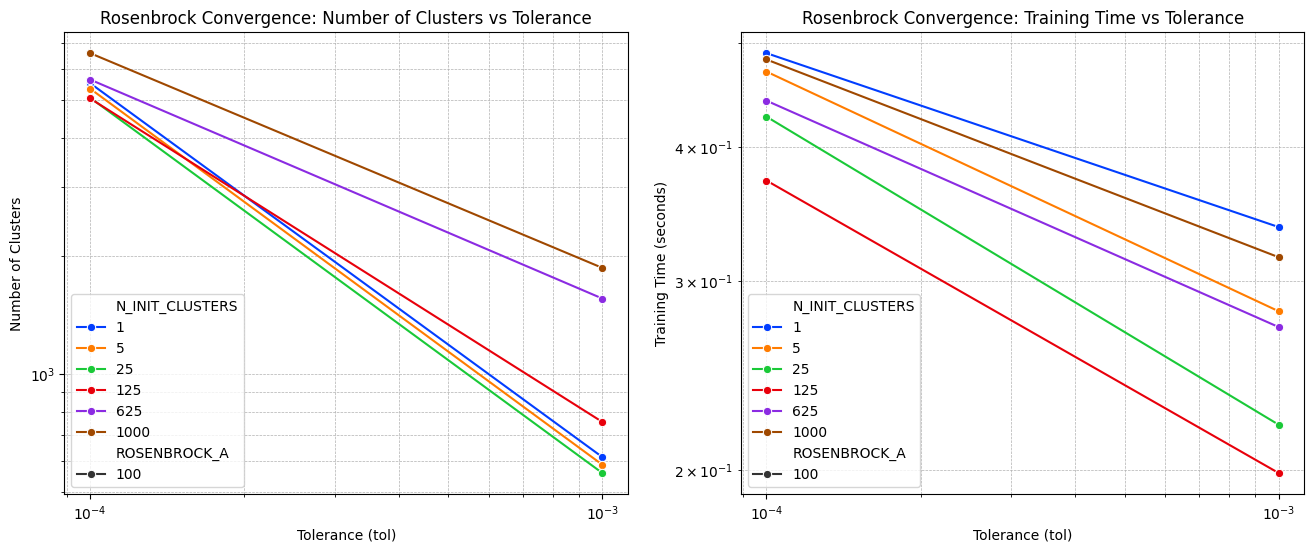

In [ ]:
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_ac_ninit,
    x="tol",
    y="max_rel_error_linf",
    hue="N_INIT_CLUSTERS",
    style="ROSENBROCK_A",
    marker="o",
    palette="bright",
)

plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Max Relative Error (Linf)")
plt.title("Rosenbrock Convergence: Max Relative Error vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_ac_ninit,
    x="tol",
    y="perct_ungauranteed",
    hue="N_INIT_CLUSTERS",
    style="ROSENBROCK_A",
    marker="o",
    palette="bright",
)
plt.xscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Percentage of Unguaranteed Points")
plt.title("Rosenbrock Convergence: Percentage of Unguaranteed Points vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_ac_ninit,
    x="tol",
    y="n_clusters",
    hue="N_INIT_CLUSTERS",
    style="ROSENBROCK_A",
    marker="o",
    palette="bright",
)

plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Number of Clusters")
plt.title("Rosenbrock Convergence: Number of Clusters vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_ac_ninit,
    x="tol",
    y="train_time_sec",
    hue="N_INIT_CLUSTERS",
    style="ROSENBROCK_A",
    marker="o",
    palette="bright",
)
plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Training Time (seconds)")
plt.title("Rosenbrock Convergence: Training Time vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

# Adaptive Clustering: Variation of Min Points per Cluster

In [ ]:
ac_mppc = ICS26_DIR / "adaptive_clustering_global_local_vs_min_pts_per_cluster"
csv_path = ac_mppc / "summary.csv"

df_ac_mppc = pd.read_csv(csv_path)

Text(0.5, 1.0, 'Correlation Heatmap: Varying N_MIN_PER_CLUSTER')

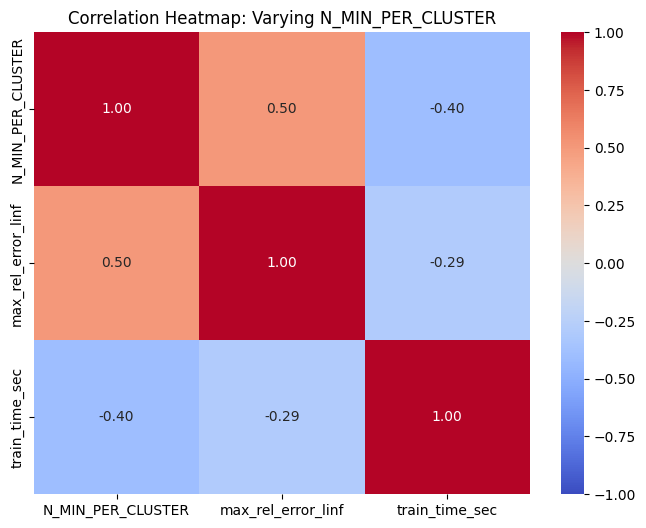

In [ ]:
cols = ["N_MIN_PER_CLUSTER", "max_rel_error_linf", "train_time_sec"]
corr_df = df_ac_mppc[cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr_df, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap: Varying N_MIN_PER_CLUSTER")

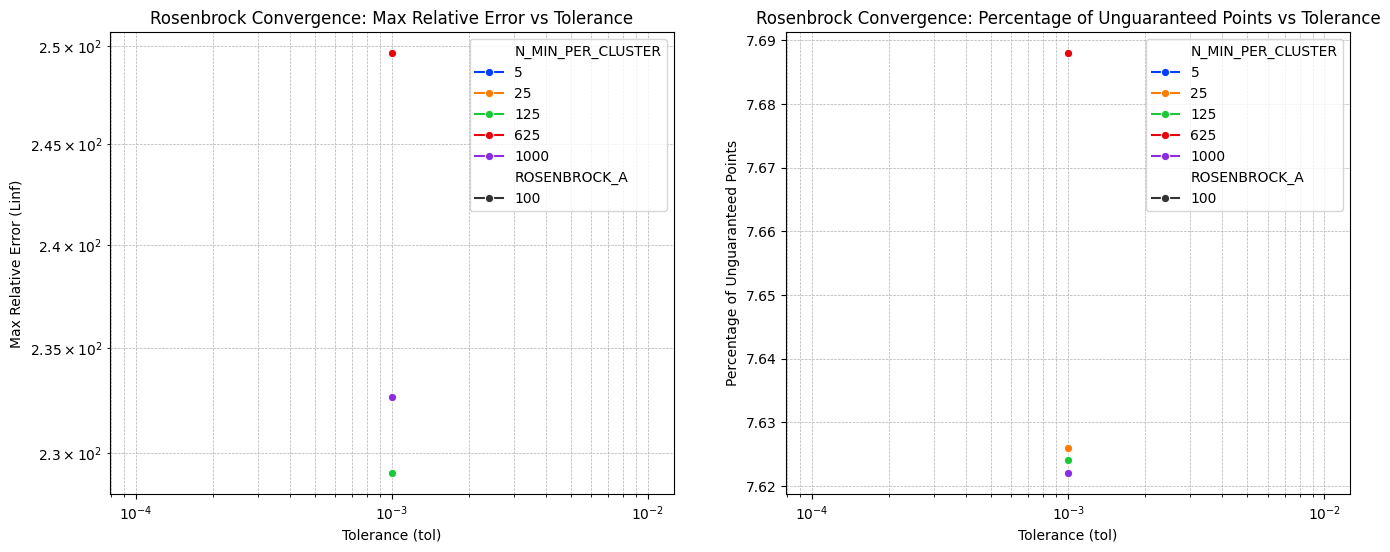

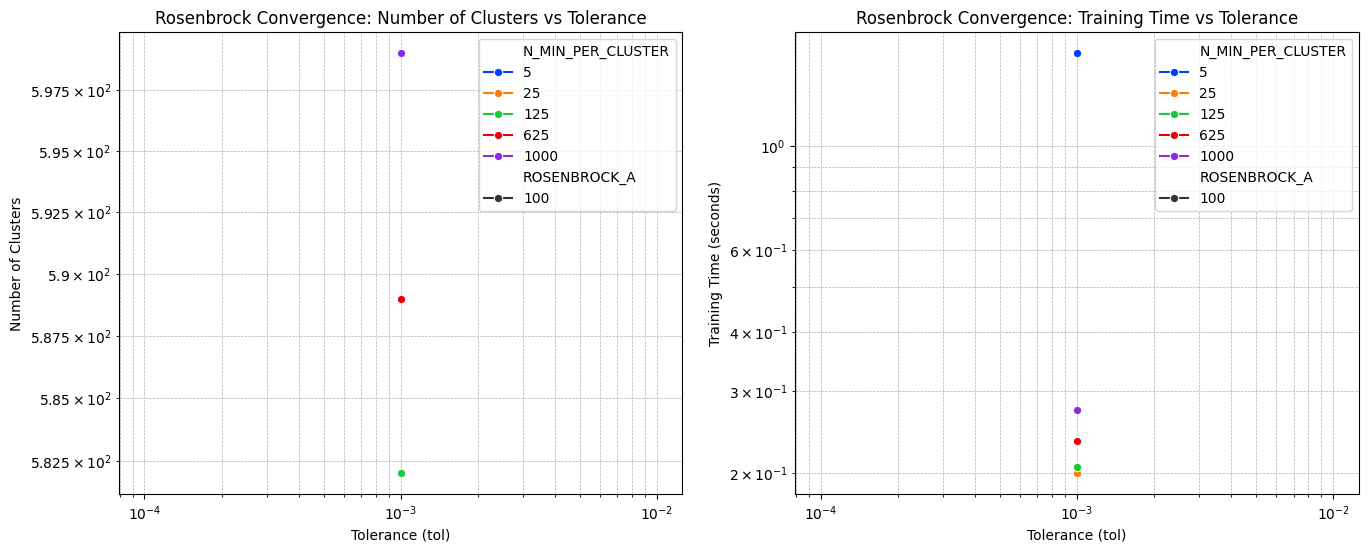

In [ ]:
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_ac_mppc,
    x="tol",
    y="max_rel_error_linf",
    hue="N_MIN_PER_CLUSTER",
    style="ROSENBROCK_A",
    marker="o",
    palette="bright",
)

plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Max Relative Error (Linf)")
plt.title("Rosenbrock Convergence: Max Relative Error vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_ac_mppc,
    x="tol",
    y="perct_ungauranteed",
    hue="N_MIN_PER_CLUSTER",
    style="ROSENBROCK_A",
    marker="o",
    palette="bright",
)
plt.xscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Percentage of Unguaranteed Points")
plt.title("Rosenbrock Convergence: Percentage of Unguaranteed Points vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_ac_mppc,
    x="tol",
    y="n_clusters",
    hue="N_MIN_PER_CLUSTER",
    style="ROSENBROCK_A",
    marker="o",
    palette="bright",
)

plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Number of Clusters")
plt.title("Rosenbrock Convergence: Number of Clusters vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_ac_mppc,
    x="tol",
    y="train_time_sec",
    hue="N_MIN_PER_CLUSTER",
    style="ROSENBROCK_A",
    marker="o",
    palette="bright",
)
plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Training Time (seconds)")
plt.title("Rosenbrock Convergence: Training Time vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

# Mahalanobis KNN Containment EDA

In [ ]:
mahalanobis_dir = ICS26_DIR / "mahalanobis_knn_containment"
csv_path = mahalanobis_dir / "summary.csv"

df_ml_knn = pd.read_csv(csv_path)

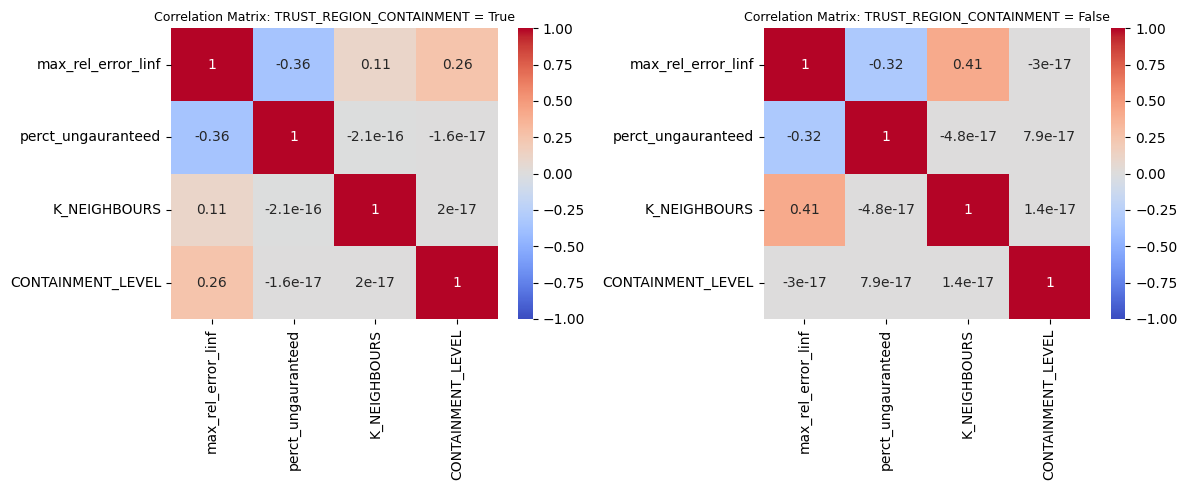

In [ ]:
cols = ["max_rel_error_linf", "perct_ungauranteed", "K_NEIGHBOURS", "CONTAINMENT_LEVEL"]
trc_col = "TRUST_REGION_CONTAINMENT"
corr_df_constrained = df_ml_knn[df_ml_knn[trc_col] == True][cols]
corr_df_unconstrained = df_ml_knn[df_ml_knn[trc_col] == False][cols]

corr_constrained = corr_df_constrained.corr()
corr_unconstrained = corr_df_unconstrained.corr()

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.heatmap(corr_constrained, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title(f"Correlation Matrix: {trc_col} = True", fontsize=9)
plt.subplot(1, 2, 2)
sns.heatmap(corr_unconstrained, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title(f"Correlation Matrix: {trc_col} = False", fontsize=9)
plt.tight_layout()

### Testing means of max_rel_error_linf for constrained vs unconstrained (CL=1)

In [ ]:
conds = df_ml_knn["CONTAINMENT_LEVEL"] == 1
max_rel_error_linf_constrained = df_ml_knn[conds & (df_ml_knn[trc_col] == True)][
    err_col
]
max_rel_error_linf_unconstrained = df_ml_knn[conds & (df_ml_knn[trc_col] == False)][
    err_col
]

t_stat, p_val = ttest_ind(
    max_rel_error_linf_constrained, max_rel_error_linf_unconstrained
)
mean_1 = max_rel_error_linf_constrained.mean()
mean_2 = max_rel_error_linf_unconstrained.mean()
print(f"Means: {mean_1:.2f} (constrained, CL=1) vs {mean_2:.2f} (unconstrained, CL=1)")
print(f"T-statistic: {t_stat}, P-value: {p_val*100:.2f}%")  # type: ignore

Means: 284.25 (constrained, CL=1) vs 5758.18 (unconstrained, CL=1)
T-statistic: -1.9349862357180643, P-value: 6.05%


### Testing means of max_rel_error_linf for CL = 1 vs CL = 2 (constrained)

In [ ]:
err_col = "max_rel_error_linf"
conds = df_ml_knn[trc_col] == True
max_rel_error_linf_cl1 = df_ml_knn[conds & (df_ml_knn["CONTAINMENT_LEVEL"] == 1)][
    err_col
]
max_rel_error_linf_cl2 = df_ml_knn[conds & (df_ml_knn["CONTAINMENT_LEVEL"] == 2)][
    err_col
]

t_stat, p_val = ttest_ind(max_rel_error_linf_cl1, max_rel_error_linf_cl2)
mean_1 = max_rel_error_linf_cl1.mean()
mean_2 = max_rel_error_linf_cl2.mean()
print(f"Means: {mean_1:.2f} (constrained, CL=1) vs {mean_2:.2f} (constrained, CL=2)")
print(f"T-statistic: {t_stat}, P-value: {p_val*100:.2f}%")  # type: ignore

Means: 284.25 (constrained, CL=1) vs 2477.13 (constrained, CL=2)
T-statistic: -2.374424703861926, P-value: 2.27%


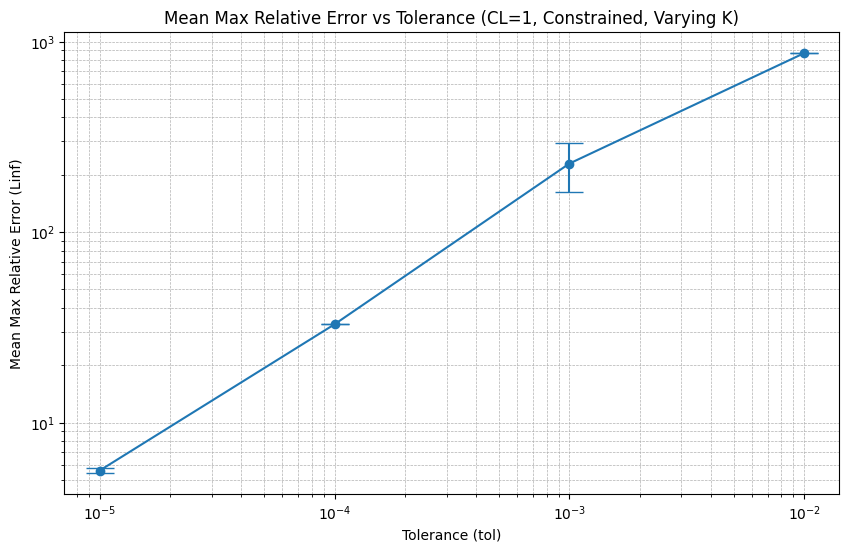

In [ ]:
cond = (df_ml_knn[trc_col] == True) & (df_ml_knn["CONTAINMENT_LEVEL"] == 1)

# Plot histograms of max_rel_error_linf for different tols with error bars
tols = sorted(df_ml_knn[cond]["tol"].unique())
plt.figure(figsize=(10, 6))
data = []
for tol in tols:
    subset = df_ml_knn[cond & (df_ml_knn["tol"] == tol)]["max_rel_error_linf"]
    _mu, _std = subset.mean(), subset.std()
    data.append((tol, _mu, _std))

tols, mus, stds = zip(*data)
plt.errorbar(tols, mus, yerr=stds, fmt="o-", capsize=10)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Mean Max Relative Error (Linf)")
plt.title("Mean Max Relative Error vs Tolerance (CL=1, Constrained, Varying K)")
plt.grid(True, which="both", ls="--", lw=0.5)

## Insights
- The mean maximum relative error (L-infinity) is lower when `TRUST_REGION_CONTAINMENT` is enabled, as compared to when it is disabled (p-value ~ 0.06).
- When `TRUST_REGION_CONTAINMENT` is enabled, the mean maximum relative error (L-infinity) is lower for containment level 1 compared to containment level 2 (p-value ~ 0.03).
- With `TRUST_REGION_CONTAINMENT` enabled, and containment level set to 1, the `kNN` value does not significantly affect the maximum relative error (L-infinity)

# Rosenbrock Convergence EDA 

In [ ]:
rosenbrock_dir = ICS26_DIR / "rosenbrock_convergence"
csv_path = rosenbrock_dir / "summary.csv"

df_rb = pd.read_csv(csv_path)
print(list(df_rb.columns))
display(df_rb)

['problem_name', 'problem_tag', 'tol', 'dim', 'n_train', 'n_test', 'n_clusters', 'max_rel_error_linf', 'max_rel_error_l2', 'n_ungauranteed', 'perct_ungauranteed', 'n_within_tol', 'perct_within_tol', 'train_time_sec', 'predict_time_sec', 'error_tag', 'ERROR_SCALING_METHOD', 'ROSENBROCK_A', 'N_INIT_CLUSTERS', 'N_MIN_PER_CLUSTER', 'K_NEIGHBOURS', 'TRUST_REGION_CONTAINMENT', 'CONTAINMENT_LEVEL', 'SYNTH_BUDGET_FACTOR']


,problem_name,problem_tag,tol,dim,n_train,n_test,n_clusters,max_rel_error_linf,max_rel_error_l2,n_ungauranteed,...,predict_time_sec,error_tag,ERROR_SCALING_METHOD,ROSENBROCK_A,N_INIT_CLUSTERS,N_MIN_PER_CLUSTER,K_NEIGHBOURS,TRUST_REGION_CONTAINMENT,CONTAINMENT_LEVEL,SYNTH_BUDGET_FACTOR
0,Rosenbrock,adaptive_clustering_global_vs_local,0.100000,2,200000,100000,34.0,15417.955562,15417.955562,3771.0,...,0.262670,NaN,global,100,25,100,5,True,1.0,200
1,Rosenbrock,adaptive_clustering_global_vs_local,0.100000,2,200000,100000,34.0,4613.996001,4613.996001,3829.0,...,0.275490,NaN,global,1,25,100,5,True,1.0,200
2,Rosenbrock,adaptive_clustering_global_vs_local,0.010000,2,200000,100000,94.0,219.225840,219.225840,6207.0,...,0.339994,NaN,global,1,25,100,5,True,1.0,200
3,Rosenbrock,adaptive_clustering_global_vs_local,0.010000,2,200000,100000,97.0,906.893302,906.893302,6204.0,...,0.279981,NaN,global,100,25,100,5,True,1.0,200
4,Rosenbrock,adaptive_clustering_global_vs_local,0.001000,2,200000,100000,560.0,258.251639,258.251639,6336.0,...,0.443990,NaN,global,100,25,100,5,True,1.0,200
5,Rosenbrock,adaptive_clustering_global_vs_local,0.001000,2,200000,100000,542.0,97.589356,97.589356,6389.0,...,0.453857,NaN,global,1,25,100,5,True,1.0,200
6,Rosenbrock,adaptive_clustering_global_vs_local,0.000100,2,200000,100000,5081.0,32.788479,32.788479,9018.0,...,1.106729,NaN,global,100,25,100,5,True,1.0,200
7,Rosenbrock,adaptive_clustering_global_vs_local,0.000100,2,200000,100000,4873.0,3.191292,3.191292,9109.0,...,1.059206,NaN,global,1,25,100,5,True,1.0,200
8,Rosenbrock,adaptive_clustering_global_vs_local,0.000010,2,200000,100000,47687.0,0.688597,0.688597,27933.0,...,7.234774,NaN,global,1,25,100,5,True,1.0,200
9,Rosenbrock,adaptive_clustering_global_vs_local,0.000010,2,200000,100000,49698.0,5.521182,5.521182,28156.0,...,7.366448,NaN,global,100,25,100,5,True,1.0,200


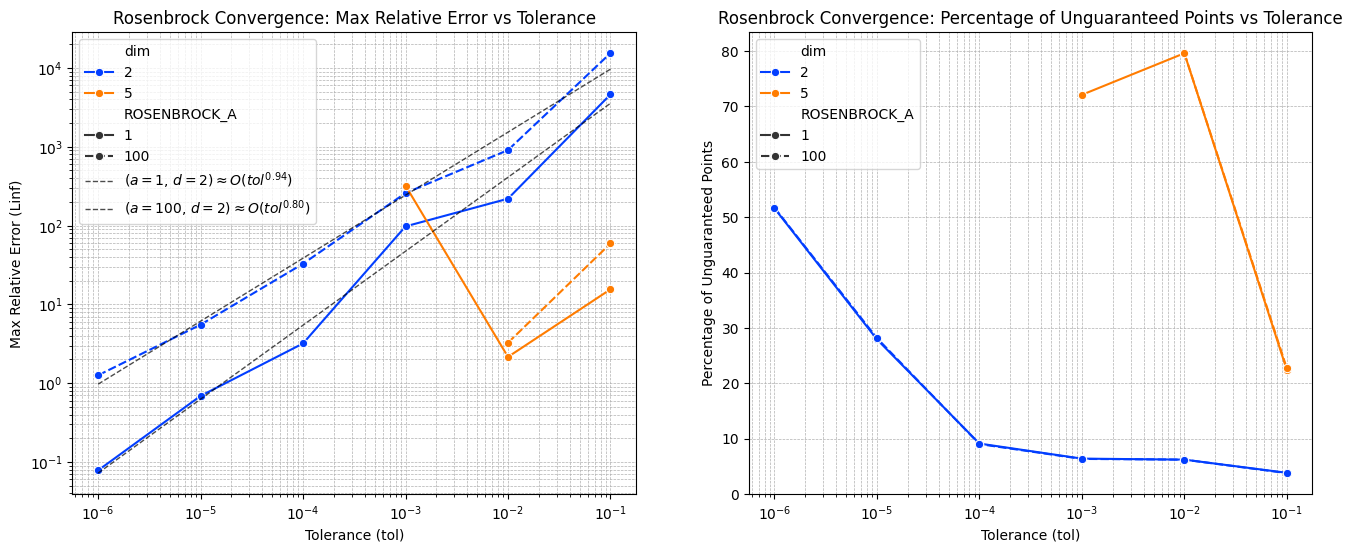

In [ ]:
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_rb,
    x="tol",
    y="max_rel_error_linf",
    hue="dim",
    style="ROSENBROCK_A",
    marker="o",
    palette="bright",
)

# Fit a line to each series to estimate convergence rate
for (error_type, a_val), group in df_rb.groupby(["dim", "ROSENBROCK_A"]):
    # Skip nan or inf values
    group = group.where(~group.isin([np.inf, -np.inf]), np.nan).dropna(
        subset=["max_rel_error_linf"]
    )
    if len(group) < 4:
        continue
    X = np.log(group["tol"]).values.reshape(-1, 1)
    y = np.log(group["max_rel_error_linf"]).values
    model = LinearRegression()
    model.fit(X, y)

    # Plot the fitted line
    x_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
    y_fit = model.predict(x_fit)
    plt.plot(
        np.exp(x_fit),
        np.exp(y_fit),
        linestyle="--",
        color="k",
        lw=1,
        alpha=0.7,
        label=rf"$(a=${a_val}, $d=${error_type}$) \approx O(tol^{{{model.coef_[0]:.2f}}})$",
    )

plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Max Relative Error (Linf)")
plt.title("Rosenbrock Convergence: Max Relative Error vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_rb,
    x="tol",
    y="perct_ungauranteed",
    hue="dim",
    style="ROSENBROCK_A",
    marker="o",
    palette="bright",
)
plt.xscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Percentage of Unguaranteed Points")
plt.title("Rosenbrock Convergence: Percentage of Unguaranteed Points vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

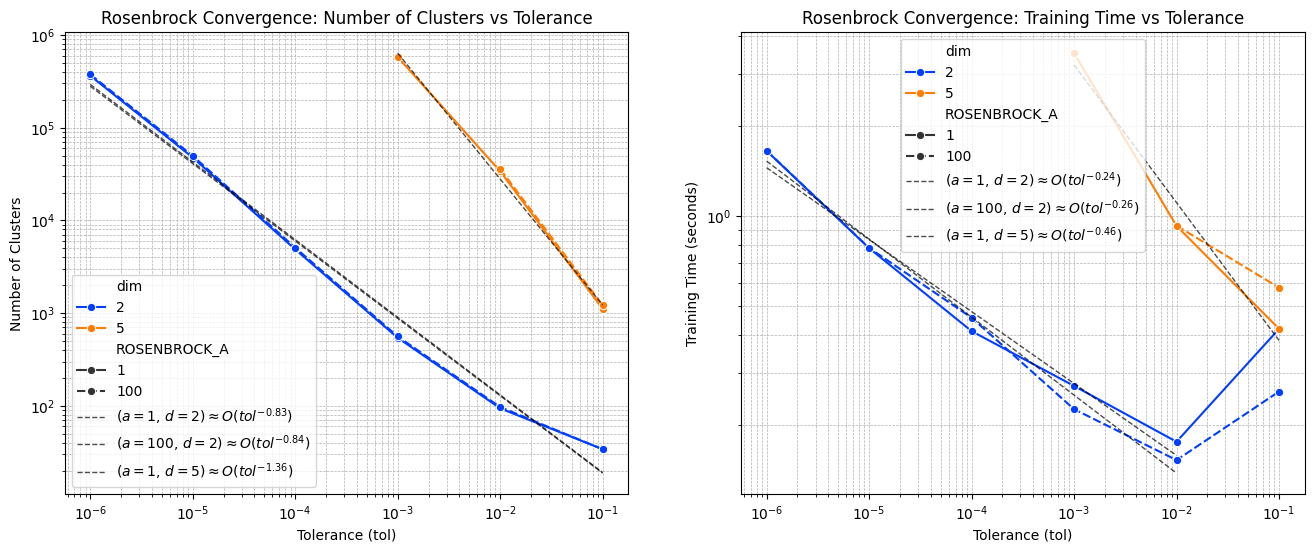

In [20]:
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.lineplot(
    data=df_rb,
    x="tol",
    y="n_clusters",
    hue="dim",
    style="ROSENBROCK_A",
    marker="o",
    palette="bright",
)
# Fit a line to each series to estimate cluster growth rate
for (error_type, a_val), group in df_rb.groupby(["dim", "ROSENBROCK_A"]):
    # Skip nan or inf values
    group = group.where(~group.isin([np.inf, -np.inf]), np.nan).dropna(
        subset=["n_clusters"]
    )
    if len(group) < 3:
        continue
    X = np.log(group["tol"]).values.reshape(-1, 1)
    y = np.log(group["n_clusters"]).values
    model = LinearRegression()
    model.fit(X, y)
    # Plot the fitted line
    x_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
    y_fit = model.predict(x_fit)
    plt.plot(
        np.exp(x_fit),
        np.exp(y_fit),
        linestyle="--",
        color="k",
        lw=1,
        alpha=0.7,
        label=rf"$(a=${a_val}, $d=${error_type}$) \approx O(tol^{{{model.coef_[0]:.2f}}})$",
    )

plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Number of Clusters")
plt.title("Rosenbrock Convergence: Number of Clusters vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)

plt.subplot(1, 2, 2)
sns.lineplot(
    data=df_rb,
    x="tol",
    y="train_time_sec",
    hue="dim",
    style="ROSENBROCK_A",
    marker="o",
    palette="bright",
)
# Fit a line to each series to estimate training time growth rate
for (error_type, a_val), group in df_rb.groupby(["dim", "ROSENBROCK_A"]):
    # Skip nan or inf values
    group = group.where(~group.isin([np.inf, -np.inf]), np.nan).dropna(
        subset=["train_time_sec"]
    )
    if len(group) < 3:
        continue
    X = np.log(group["tol"]).values.reshape(-1, 1)
    y = np.log(group["train_time_sec"]).values

    # if dim == 2 ignore first data point to avoid skewing
    if error_type == 2:
        X = X[1:]
        y = y[1:]
    model = LinearRegression()
    model.fit(X, y)
    # Plot the fitted line
    x_fit = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
    y_fit = model.predict(x_fit)
    plt.plot(
        np.exp(x_fit),
        np.exp(y_fit),
        linestyle="--",
        color="k",
        lw=1,
        alpha=0.7,
        label=rf"$(a=${a_val}, $d=${error_type}$) \approx O(tol^{{{model.coef_[0]:.2f}}})$",
    )
plt.legend()
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Tolerance (tol)")
plt.ylabel("Training Time (seconds)")
plt.title("Rosenbrock Convergence: Training Time vs Tolerance")
plt.grid(True, which="both", ls="--", lw=0.5)